# TP – Méthodes d'optimisation implémentées avec NumPy
Trois exercices (régression OLS/ridge/noyau RBF, classification MLP 3 couches, clustering par centroïdes lisses),
sept optimiseurs écrits à la main : **GD, GD+recherche de pas, SGD, Momentum, AdaGrad, RMSprop, Adam**.


In [ ]:
# Configuration
import os, time, math, json, sys, zipfile, warnings
import numpy as np, pandas as pd
import matplotlib
try:
    import google.colab  # noqa
    IN_COLAB = True
except Exception:
    IN_COLAB = False
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix,
                             adjusted_rand_score, normalized_mutual_info_score, silhouette_score,
                             mean_absolute_error, r2_score)
np.seterr(all="ignore")
SHOW = IN_COLAB                       # afficher les figures dans le notebook

DATA_DIR = "/content/data" if IN_COLAB else "./data"
OUT_DIR  = "/content/resultats" if IN_COLAB else "./resultats"
FILES = dict(reg_nonlinear="regression_nonlinear.csv", reg_diabetes="regression_diabetes.csv",
             clf_spiral="classification_spiral3.csv", clf_iris="classification_iris.csv",
             mnist="mnist_50k_10k_10k.npz", fashion="fashion_mnist_50k_10k_10k.npz",
             clu_blobs="clustering_blobs3.csv", clu_wine="clustering_wine.csv")
SEEDS = [42, 123, 2024]
QUICK = False                         # True = budgets minuscules, uniquement pour vérifier que tout tourne

CFG = dict(
    # régression (float64)
    reg_epochs_full=1500, reg_epochs_mb=150, reg_batch=32,
    # classification CSV
    clf_epochs_full=1000, clf_epochs_mb=150, clf_batch=dict(spiral=32, iris=16),
    # classification images (budget initial de la fiche : 8 époques -> à prolonger si les courbes baissent encore)
    img_epochs=8, img_tune_epochs=3, img_batch=1024, img_mon_n=10000,
    # clustering
    clu_csv_epochs_full=300, clu_csv_epochs_mb=100, clu_csv_batch=64, lloyd_csv_iters=50,
    clu_img_epochs=8, clu_img_tune_epochs=3, clu_img_batch=2048, lloyd_img_iters=20,
    tau_csv=0.25, tau_img=5.0,
    img_subsample=None,               # ex. 5000 pour tester vite sur images (None = 50k/10k/10k complets)
)
RUN = dict(regression=True, classification=True, clustering=True)
IMG_KEYS = ["mnist", "fashion"]

def apply_quick():
    global SEEDS
    SEEDS = [42]
    CFG.update(reg_epochs_full=100, reg_epochs_mb=10, clf_epochs_full=60, clf_epochs_mb=8,
               img_epochs=2, img_tune_epochs=1, img_subsample=3000,
               clu_csv_epochs_full=40, clu_csv_epochs_mb=8, lloyd_csv_iters=10,
               clu_img_epochs=2, clu_img_tune_epochs=1, lloyd_img_iters=4)
if QUICK: apply_quick()

METHODS = ["GD", "GD+LS", "SGD", "Momentum", "AdaGrad", "RMSprop", "Adam"]
FULL = {"GD", "GD+LS"}                # méthodes à lot complet
COL = {m: plt.cm.tab10(i) for i, m in enumerate(METHODS + ["Lloyd"])}
FIG_DIR = os.path.join(OUT_DIR, "figures"); TAB_DIR = os.path.join(OUT_DIR, "tables")
for d in (OUT_DIR, FIG_DIR, TAB_DIR): os.makedirs(d, exist_ok=True)

In [ ]:
# Données
def ensure_data():
    missing = [f for f in FILES.values() if not os.path.exists(os.path.join(DATA_DIR, f))]
    if not missing:
        print("Tous les fichiers sont présents dans", DATA_DIR); return
    print("Fichiers manquants :", missing)
    if IN_COLAB:
        from google.colab import files
        os.makedirs(DATA_DIR, exist_ok=True)
        print("Sélectionnez les fichiers manquants (les NPZ sont gros : préférez Drive, voir ci-dessous).")
        up = files.upload()
        for name, content in up.items():
            with open(os.path.join(DATA_DIR, name), "wb") as f: f.write(content)
    else:
        print("Placez-les dans", DATA_DIR)

In [ ]:
ensure_data()

Fichiers manquants : ['regression_nonlinear.csv', 'regression_diabetes.csv', 'classification_spiral3.csv', 'classification_iris.csv', 'mnist_50k_10k_10k.npz', 'fashion_mnist_50k_10k_10k.npz', 'clustering_blobs3.csv', 'clustering_wine.csv']
Sélectionnez les fichiers manquants (les NPZ sont gros : préférez Drive, voir ci-dessous).


Saving classification_spiral3.csv to classification_spiral3.csv
Saving clustering_blobs3.csv to clustering_blobs3.csv
Saving regression_nonlinear.csv to regression_nonlinear.csv


In [ ]:
# Noyau commun : optimiseurs, entraînement, vérification des gradients
class Optimizer:
    """Mises à jour de la fiche, écrites à la main. Mémoires initialisées à zéro, opérations composante par composante."""
    def __init__(s, name, eta, dim, dtype, mu=.9, rho=.9, b1=.9, b2=.999, eps=1e-8):
        s.name, s.eta = name, (None if eta is None else float(eta))
        s.mu, s.rho, s.b1, s.b2, s.eps, s.t = mu, rho, b1, b2, eps, 0
        s.v = np.zeros(dim, dtype); s.s = np.zeros(dim, dtype); s.m = np.zeros(dim, dtype)
    def step(s, th, g, eta=None):
        s.t += 1; e = s.eta if eta is None else float(eta); n = s.name
        if n in ("GD", "GD+LS", "SGD"):
            new = th - e * g
        elif n == "Momentum":                       # v_t = mu v_{t-1} + g_t ; th -= eta v_t
            s.v = s.mu * s.v + g; new = th - e * s.v
        elif n == "AdaGrad":                        # s_t = s_{t-1} + g^2
            s.s = s.s + g * g; new = th - e * g / (np.sqrt(s.s) + s.eps)
        elif n == "RMSprop":                        # s_t = rho s + (1-rho) g^2
            s.s = s.rho * s.s + (1 - s.rho) * g * g; new = th - e * g / (np.sqrt(s.s) + s.eps)
        elif n == "Adam":                           # moments + correction de biais
            s.m = s.b1 * s.m + (1 - s.b1) * g; s.s = s.b2 * s.s + (1 - s.b2) * g * g
            mh = s.m / (1 - s.b1 ** s.t); sh = s.s / (1 - s.b2 ** s.t)
            new = th - e * mh / (np.sqrt(sh) + s.eps)
        else: raise ValueError(n)
        return new.astype(th.dtype, copy=False)

def golden_search(f, hi, iters=12):
    """Recherche numérique bornée (section dorée) de min_{0<=eta<=hi} f(eta). Approchée ; coûte iters+2 évaluations."""
    fw = lambda e: (lambda v: v if np.isfinite(v) else 1e300)(f(e))
    gr = (math.sqrt(5) - 1) / 2; a, b = 0.0, float(hi)
    c = b - gr * (b - a); d = a + gr * (b - a); fc, fd = fw(c), fw(d); n = 2
    for _ in range(iters):
        if fc < fd: b, d, fd = d, c, fc; c = b - gr * (b - a); fc = fw(c)
        else:       a, c, fc = c, d, fd; d = a + gr * (b - a); fd = fw(d)
        n += 1
    return (c if fc < fd else d), n

class Problem:
    n = dim = None
    def theta0(s, seed): raise NotImplementedError
    def loss(s, th, idx=None): raise NotImplementedError          # objectif (régularisation incluse) sur lot idx (None = tout le train)
    def grad(s, th, idx=None): raise NotImplementedError          # gradient du même objectif
    def monitor(s, th, light=False): raise NotImplementedError    # dict avec au moins 'val_score' (à minimiser)
    def final(s, th): raise NotImplementedError
    def line_search(s, th, g, eta_max):
        return golden_search(lambda e: s.loss(th - float(e) * g), eta_max)

def train(prob, method, eta, epochs, batch, seed, ls_max=1.0, light=False):
    rng = np.random.default_rng(seed)               # même ordre de mini-lots pour toutes les méthodes à graine égale
    th = prob.theta0(seed).copy()                   # même initialisation pour toutes les méthodes à graine égale
    opt = Optimizer(method, eta, th.size, th.dtype)
    c = dict(updates=0, grad_calls=0, grad_samples=0, loss_calls=0)
    ttrain, diverged = 0.0, False
    m = prob.monitor(th, light); m.update(epoch=0, time=0.0, updates=0); hist = [m]
    best_score, best_th, best_ep = m["val_score"], th.copy(), 0
    for ep in range(1, epochs + 1):
        t0 = time.perf_counter()
        if method in FULL:
            g = prob.grad(th, None); c["grad_calls"] += 1; c["grad_samples"] += prob.n
            if method == "GD+LS":
                e, nl = prob.line_search(th, g, ls_max); c["loss_calls"] += nl; th = (th - float(e) * g).astype(th.dtype, copy=False)
            else:
                th = opt.step(th, g)
            c["updates"] += 1
        else:
            perm = rng.permutation(prob.n)
            for k in range(0, prob.n, batch):
                idx = perm[k:k + batch]; g = prob.grad(th, idx); th = opt.step(th, g)
                c["updates"] += 1; c["grad_calls"] += 1; c["grad_samples"] += len(idx)
        ttrain += time.perf_counter() - t0
        if not np.all(np.isfinite(th)): diverged = True; break
        m = prob.monitor(th, light); m.update(epoch=ep, time=ttrain, updates=c["updates"]); hist.append(m)
        if m["val_score"] < best_score: best_score, best_th, best_ep = m["val_score"], th.copy(), ep
    return dict(hist=hist, best_score=best_score, best_epoch=best_ep, best_theta=best_th, counts=c,
                time=ttrain, diverged=diverged, epochs_run=len(hist) - 1)

def tune_eta(prob, method, grid, epochs, batch, seed, ls_max):
    if method == "GD+LS": return None, {}
    sc = {}
    for e in grid:
        r = train(prob, method, e, epochs, batch, seed, ls_max, light=True)
        sc[e] = np.inf if r["diverged"] else r["best_score"]
    return min(sc, key=sc.get), sc

def run_experiment(prob, meta, grids, ep_full, ep_mb, batch, tune_full, tune_mb, ls_max, seeds=None):
    seeds = seeds or SEEDS; rows, store, tun = [], {}, []
    for m in METHODS:
        full = m in FULL
        eta, sc = tune_eta(prob, m, grids.get(m), tune_full if full else tune_mb, batch, seeds[0], ls_max)
        for e, v in sc.items(): tun.append({**meta, "method": m, "eta": e, "val_score_tuning": v})
        for s in seeds:
            r = train(prob, m, eta, ep_full if full else ep_mb, batch, s, ls_max)
            rows.append({**meta, "method": m, "seed": s, "eta": eta, "best_epoch": r["best_epoch"], "best_val": r["best_score"],
                         "time_s": r["time"], **r["counts"], "epochs_run": r["epochs_run"], "diverged": r["diverged"],
                         **prob.final(r["best_theta"])})
            if s == seeds[0]: store[m] = dict(hist=r["hist"], theta=r["best_theta"])
        print(f"  {meta.get('dataset')}/{meta.get('model','')} {m:9s} eta={eta} val={np.mean([x['best_val'] for x in rows if x['method']==m]):.4g}")
    return rows, store, tun

def grad_check(prob, th, idx=None, k=10, h=1e-5, seed=0):
    """Différences finies centrales sur k coordonnées ; renvoie (erreur relative max, moyenne)."""
    rng = np.random.default_rng(seed); g = prob.grad(th, idx); errs = []
    for i in rng.choice(th.size, min(k, th.size), replace=False):
        e = np.zeros_like(th); e[i] = h
        fd = (prob.loss(th + e, idx) - prob.loss(th - e, idx)) / (2 * h)
        errs.append(abs(g[i] - fd) / max(1e-12, abs(g[i]) + abs(fd)))
    return float(np.max(errs)), float(np.mean(errs))

# --- tableaux, figures utilitaires
def aggregate(df, keys, metrics):
    g = df.groupby(keys + ["method"], sort=False, dropna=False)
    mean = g[metrics].mean().add_suffix("_mean"); std = g[metrics].std(ddof=0).add_suffix("_std")
    n = g.size().rename("n_seeds")
    return mean.join(std).join(n).reset_index()

def fmt_table(agg, metrics):
    out = agg[[c for c in agg.columns if not c.endswith(("_mean", "_std"))]].copy()
    for m in metrics:
        out[m] = [("N/A" if not np.isfinite(a) else f"{a:.4g} ± {0 if not np.isfinite(b) else b:.2g}")
                  for a, b in zip(agg[m + "_mean"], agg[m + "_std"])]
    return out

def savefig(fig, name):
    fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, name), dpi=130)
    if SHOW: plt.show()
    plt.close(fig)

def plot_curves(store, panels, title, name):
    fig, axs = plt.subplots(1, len(panels), figsize=(5.3 * len(panels), 4)); axs = np.atleast_1d(axs)
    for ax, (xk, yks, yl, logy) in zip(axs, panels):
        for m, st in store.items():
            h = st["hist"]; x = [e[xk] for e in h]
            for j, yk in enumerate(yks):
                ax.plot(x, [e.get(yk, np.nan) for e in h], color=COL[m], ls=["-", "--"][j], label=m if j == 0 else None)
        ax.set_xlabel("époque" if xk == "epoch" else "temps d'entraînement (s)"); ax.set_ylabel(yl); ax.grid(alpha=.3)
        if logy: ax.set_yscale("log")
    axs[0].legend(fontsize=7); fig.suptitle(title, fontsize=10); savefig(fig, name)

def pca_fit(X, k=2):
    X = np.asarray(X, dtype=np.float64); mu = X.mean(0); Xc = X - mu
    w, V = np.linalg.eigh(Xc.T @ Xc / len(X)); return mu, V[:, ::-1][:, :k]

def best_method(df):
    return df.groupby("method")["best_val"].mean().idxmin()

def load_csv_split(path):
    df = pd.read_csv(path)
    if "split" in df:
        s = df["split"].astype(str).str.lower().str[:2]
        m = {k: (s == v).values for k, v in dict(train="tr", val="va", test="te").items()}
    else:
        rng = np.random.default_rng(0); p = rng.permutation(len(df)); n = len(df)
        m = {k: np.zeros(n, bool) for k in ("train", "val", "test")}
        m["train"][p[:int(.6 * n)]] = 1; m["val"][p[int(.6 * n):int(.8 * n)]] = 1; m["test"][p[int(.8 * n):]] = 1
    return df, m

In [ ]:
# Exercice 1 : régression (OLS, ridge, ridge à noyau RBF)
def rbf(A, B, sigma):
    D = (A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T
    return np.exp(-np.maximum(D, 0) / (2 * sigma ** 2))

class QuadProblem(Problem):
    """J(th) = ||A th - y||^2/(2n) + lam/2 th' R th ;  grad = A'(A th - y)/n + lam R th.
    Linéaire : A=[1,X], R=P=diag(0,1..1).  Noyau : A=K, R=K (th = a)."""
    def __init__(s, A, y, Av, yv, At, yt, lam, R, ymu, ysd):
        s.A, s.y, s.Av, s.At, s.yv, s.yt, s.lam, s.R, s.ymu, s.ysd = A, y, Av, At, yv, yt, lam, R, ymu, ysd
        s.n, s.dim = A.shape
    def Rv(s, v): return s.R @ v if s.R.ndim == 2 else s.R * v
    def theta0(s, seed): return np.random.default_rng(seed).normal(0, .1, s.dim)
    def _ab(s, idx): return (s.A, s.y) if idx is None else (s.A[idx], s.y[idx])
    def loss(s, th, idx=None):
        A, y = s._ab(idx); r = A @ th - y
        return float(r @ r / (2 * len(y)) + .5 * s.lam * th @ s.Rv(th))
    def grad(s, th, idx=None):
        A, y = s._ab(idx); return A.T @ (A @ th - y) / len(y) + s.lam * s.Rv(th)
    def line_search(s, th, g, eta_max):
        # J est quadratique : phi(eta)=J(th-eta g) a pour dérivée -g'(H(th-eta g)-b) = -g'g + eta g'Hg (car g = H th - b),
        # nulle en eta* = g'g / g'Hg ; c'est un minimum si g'Hg>0 (H définie positive). Pas d'évaluation de perte requise.
        Hg = s.A.T @ (s.A @ g) / s.n + s.lam * s.Rv(g); den = g @ Hg
        return (float(g @ g / den) if den > 0 else 0.0), 0
    def pred(s, th, A): return (A @ th) * s.ysd + s.ymu
    def monitor(s, th, light=False):
        v = float(np.sqrt(np.mean((s.pred(th, s.Av) - s.yv) ** 2)))
        d = dict(val_rmse=v, val_score=v)
        if not light: d["train_loss"] = s.loss(th)
        return d
    def final(s, th):
        p = s.pred(th, s.At); e = p - s.yt
        return dict(test_mse=float(np.mean(e ** 2)), test_rmse=float(np.sqrt(np.mean(e ** 2))),
                    test_mae=float(np.mean(np.abs(e))), test_r2=float(r2_score(s.yt, p)))

def cf_linear(A, y, lam, P):
    n = len(y); H = A.T @ A / n + lam * np.diag(P); b = A.T @ y / n
    try: return np.linalg.solve(H, b)
    except np.linalg.LinAlgError: return np.linalg.lstsq(H, b, rcond=None)[0]
def cf_kernel(K, y, lam): return np.linalg.solve(K + len(y) * lam * np.eye(len(y)), y)   # a* = (K + n lam I)^-1 y

def run_regression(key, name):
    path = os.path.join(DATA_DIR, FILES[key]); df, m = load_csv_split(path)
    feats = [c for c in df.columns if c not in ("y", "split")]
    X = df[feats].values.astype(float); y = df["y"].values.astype(float)
    Xtr, Xva, Xte, ytr, yva, yte = X[m["train"]], X[m["val"]], X[m["test"]], y[m["train"]], y[m["val"]], y[m["test"]]
    mu, sd = Xtr.mean(0), Xtr.std(0); sd[sd == 0] = 1; Z = lambda a: (a - mu) / sd     # statistiques du train seulement
    ymu, ysd = ytr.mean(), ytr.std(); ys = (ytr - ymu) / ysd
    Ztr, Zva, Zte = Z(Xtr), Z(Xva), Z(Xte); d = Ztr.shape[1]
    print(f"[{name}] train/val/test = {len(ytr)}/{len(yva)}/{len(yte)}, variables={feats}")
    add1 = lambda a: np.hstack([np.ones((len(a), 1)), a]); Atr, Ava, Ate = add1(Ztr), add1(Zva), add1(Zte)
    P = np.r_[0., np.ones(d)]
    rm = lambda A, th: float(np.sqrt(np.mean(((A @ th) * ysd + ymu - yva) ** 2)))
    # choix de lambda / sigma sur la validation (via solutions de contrôle exactes, uniquement pour la sélection)
    sel = []
    lam_grid = np.logspace(-4, 1, 11)
    for lam in lam_grid: sel.append(dict(model="ridge", lam=lam, sigma=np.nan, val_rmse=rm(Ava, cf_linear(Atr, ys, lam, P))))
    sig_grid = np.sqrt(d) * np.array([.25, .5, 1, 2, 4]); lamk_grid = np.logspace(-6, 0, 7)
    for sg in sig_grid:
        K = rbf(Ztr, Ztr, sg); Kv = rbf(Zva, Ztr, sg)
        for lam in lamk_grid: sel.append(dict(model="kernel", lam=lam, sigma=sg, val_rmse=rm(Kv, cf_kernel(K, ys, lam))))
    sel = pd.DataFrame(sel); sel.insert(0, "dataset", name); sel.to_csv(os.path.join(TAB_DIR, f"reg_{name}_selection_lambda_sigma.csv"), index=False)
    br = sel[sel.model == "ridge"].sort_values("val_rmse").iloc[0]; bk = sel[sel.model == "kernel"].sort_values("val_rmse").iloc[0]
    models = [("OLS", 0.0, np.nan), ("ridge", float(br.lam), np.nan), ("kernel-ridge", float(bk.lam), float(bk.sigma))]
    rows, gc, ctrl, stores, tuns = [], [], [], {}, []
    for mod, lam, sg in models:
        if mod == "kernel-ridge":
            K = rbf(Ztr, Ztr, sg); prob = QuadProblem(K, ys, rbf(Zva, Ztr, sg), yva, rbf(Zte, Ztr, sg), yte, lam, K, ymu, ysd)
            H = K @ K / prob.n + lam * K; th_c = cf_kernel(K, ys, lam)
        else:
            prob = QuadProblem(Atr, ys, Ava, yva, Ate, yte, lam, P, ymu, ysd)
            H = Atr.T @ Atr / prob.n + lam * np.diag(P); th_c = cf_linear(Atr, ys, lam, P)
        r_full = grad_check(prob, prob.theta0(0)); r_b = grad_check(prob, prob.theta0(0), idx=np.arange(0, prob.n, 3))
        gc.append(dict(dataset=name, model=mod, max_rel_err_full=r_full[0], mean_rel_err_full=r_full[1], max_rel_err_batch=r_b[0]))
        ctrl.append(dict(dataset=name, model=mod, lam=lam, sigma=sg, **prob.final(th_c), grad_norm_at_closed_form=float(np.linalg.norm(prob.grad(th_c)))))
        L = float(np.linalg.eigvalsh((H + H.T) / 2).max())
        f = lambda fs: [x / L for x in fs]
        grids = dict(GD=f([.05, .1, .3, .6, 1, 1.5, 1.9]), SGD=f([.02, .05, .1, .3, .6, 1]), Momentum=f([.005, .01, .03, .1, .2, .5]),
                     AdaGrad=[1e-3, 3e-3, 1e-2, 3e-2, 1e-1, .3], RMSprop=[1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2], Adam=[1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, .1])
        meta = dict(exercise="regression", dataset=name, model=mod, lam=lam, sigma=sg)
        r, st, tu = run_experiment(prob, meta, grids, CFG["reg_epochs_full"], CFG["reg_epochs_mb"], CFG["reg_batch"],
                                   CFG["reg_epochs_full"], CFG["reg_epochs_mb"], 1.0)
        rows += r; tuns += tu; stores[mod] = (prob, st)
        plot_curves(st, [("epoch", ["train_loss"], "objectif d'entraînement J", True), ("epoch", ["val_rmse"], "RMSE validation (unité d'origine)", True),
                         ("time", ["val_rmse"], "RMSE validation (unité d'origine)", True)],
                    f"{name} – {mod} – train/val, graine {SEEDS[0]}", f"reg_{name}_{mod}_curves.png")
        dm = pd.DataFrame(r); bm = best_method(dm); pr, tr = stores[mod]; p = tr[bm]["theta"]
        A_te = prob.At; pt = prob.pred(p, A_te); res = pt - yte
        fig, ax = plt.subplots(1, 2, figsize=(10, 4))
        ax[0].scatter(yte, pt, s=14); lo, hi = min(yte.min(), pt.min()), max(yte.max(), pt.max()); ax[0].plot([lo, hi], [lo, hi], "k--")
        ax[0].set_xlabel("valeur réelle"); ax[0].set_ylabel("valeur prédite"); ax[0].set_title("prédit vs réel (diagonale en pointillé)")
        ax[1].hist(res, bins=20); ax[1].set_xlabel("résidu (prédit − réel)"); ax[1].set_ylabel("effectif"); ax[1].set_title("histogramme des résidus")
        fig.suptitle(f"{name} – {mod} – test – méthode {bm} (retenue sur validation), graine {SEEDS[0]}", fontsize=10); savefig(fig, f"reg_{name}_{mod}_test_pred_resid.png")
        stores[mod] = (prob, tr, bm)
    if d == 2:                                   # visualisation de la fonction cible et des prédictions
        gx = np.linspace(Ztr[:, 0].min() - .3, Ztr[:, 0].max() + .3, 80); gy = np.linspace(Ztr[:, 1].min() - .3, Ztr[:, 1].max() + .3, 80)
        G = np.c_[np.repeat(gx, 80), np.tile(gy, 80)]; fig, axs = plt.subplots(1, 3, figsize=(15, 4.3))
        sc = axs[0].scatter(Ztr[:, 0], Ztr[:, 1], c=ytr, s=14, cmap="viridis"); plt.colorbar(sc, ax=axs[0], label="y"); axs[0].set_title("données d'entraînement (cible)")
        for ax, mod in zip(axs[1:], ["ridge", "kernel-ridge"]):
            prob, st, bm = stores[mod]; th = st[bm]["theta"]; lam_, sg_ = [(l, s_) for (mm, l, s_) in models if mm == mod][0]
            Agrid = add1(G) if mod == "ridge" else rbf(G, Ztr, sg_)
            im = ax.contourf(gx, gy, ((Agrid @ th) * ysd + ymu).reshape(80, 80).T, 25, cmap="viridis"); plt.colorbar(im, ax=ax, label="y prédit")
            ax.scatter(Zte[:, 0], Zte[:, 1], c="w", edgecolors="k", s=12); ax.set_title(f"{mod} ({bm}) – points test en blanc")
        for ax in axs: ax.set_xlabel("x1 (standardisé)"); ax.set_ylabel("x2 (standardisé)")
        fig.suptitle(f"{name} – fonction cible et prédictions, graine {SEEDS[0]}"); savefig(fig, f"reg_{name}_surface.png")
    else:                                        # carte de corrélation
        M = np.c_[Ztr, ytr]; C = np.corrcoef(M.T); fig, ax = plt.subplots(figsize=(7, 6))
        im = ax.imshow(C, cmap="coolwarm", vmin=-1, vmax=1); plt.colorbar(im, label="corrélation de Pearson")
        lab = feats + ["y"]; ax.set_xticks(range(len(lab))); ax.set_xticklabels(lab, rotation=90); ax.set_yticks(range(len(lab))); ax.set_yticklabels(lab)
        ax.set_title(f"{name} – corrélations (train)"); savefig(fig, f"reg_{name}_correlation.png")
    pd.DataFrame(gc).to_csv(os.path.join(TAB_DIR, f"reg_{name}_gradcheck.csv"), index=False)
    pd.DataFrame(ctrl).to_csv(os.path.join(TAB_DIR, f"reg_{name}_closed_form_control.csv"), index=False)
    pd.DataFrame(tuns).to_csv(os.path.join(TAB_DIR, f"reg_{name}_eta_tuning.csv"), index=False)
    return rows

REG_M = ["best_epoch", "best_val", "test_mse", "test_rmse", "test_mae", "test_r2", "time_s", "updates", "grad_calls", "loss_calls"]

In [ ]:
# Exercice 2 : classification multiclasse (MLP tanh à trois couches)
def softmax_rows(Z):
    Z = Z - Z.max(1, keepdims=True); E = np.exp(Z); return E / E.sum(1, keepdims=True)

class MLPProblem(Problem):
    def __init__(s, Xtr, ytr, Xva, yva, Xte, yte, sizes, lam=1e-4, dtype=np.float64, mon_n=None):
        s.Xtr, s.ytr, s.Xva, s.yva, s.Xte, s.yte = [np.asarray(a, dtype if a.ndim == 2 else np.int64) for a in (Xtr, ytr, Xva, yva, Xte, yte)]
        s.sizes, s.lam, s.dtype, s.n = sizes, lam, dtype, len(ytr); s.K = sizes[-1]
        s.shapes = [];
        for i in range(3): s.shapes += [(sizes[i], sizes[i + 1]), (sizes[i + 1],)]
        s.dim = int(sum(np.prod(sh) for sh in s.shapes))
        mn = mon_n or s.n; s.Xm, s.ym = s.Xtr[:mn], s.ytr[:mn]          # sous-ensemble fixe pour les courbes d'entraînement
    def theta0(s, seed):                                                # Xavier (normal, var = 2/(fan_in+fan_out)), biais nuls
        rng = np.random.default_rng(seed); p = []
        for i in range(3):
            p += [rng.normal(0, math.sqrt(2 / (s.sizes[i] + s.sizes[i + 1])), (s.sizes[i], s.sizes[i + 1])).ravel(), np.zeros(s.sizes[i + 1])]
        return np.concatenate(p).astype(s.dtype)
    def unpack(s, th):
        out, o = [], 0
        for i in range(0, 6, 2):
            a, b = int(np.prod(s.shapes[i])), int(np.prod(s.shapes[i + 1]))
            out.append((th[o:o + a].reshape(s.shapes[i]), th[o + a:o + a + b])); o += a + b
        return out
    def forward(s, th, X):
        (W1, b1), (W2, b2), (W3, b3) = s.unpack(th)
        H1 = np.tanh(X @ W1 + b1); H2 = np.tanh(H1 @ W2 + b2); return H1, H2, H2 @ W3 + b3
    @staticmethod
    def ce_vec(Z, y):
        m = Z.max(1, keepdims=True); return m[:, 0] + np.log(np.exp(Z - m).sum(1)) - Z[np.arange(len(y)), y]
    def reg(s, th): return .5 * s.lam * sum(float((W.astype(np.float64) ** 2).sum()) for W, _ in s.unpack(th))
    def _xy(s, idx): return (s.Xtr, s.ytr) if idx is None else (s.Xtr[idx], s.ytr[idx])
    def loss(s, th, idx=None):
        X, y = s._xy(idx); return float(s.ce_vec(s.forward(th, X)[2], y).mean()) + s.reg(th)
    def grad(s, th, idx=None):
        X, y = s._xy(idx); B = len(y); H1, H2, Z = s.forward(th, X)
        (W1, _), (W2, _), (W3, _) = s.unpack(th)
        D3 = softmax_rows(Z); D3[np.arange(B), y] -= 1; D3 /= B                    # (P - Y)/|B|
        D2 = (D3 @ W3.T) * (1 - H2 ** 2); D1 = (D2 @ W2.T) * (1 - H1 ** 2)
        g = np.concatenate([(X.T @ D1 + s.lam * W1).ravel(), D1.sum(0), (H1.T @ D2 + s.lam * W2).ravel(), D2.sum(0),
                            (H2.T @ D3 + s.lam * W3).ravel(), D3.sum(0)])         # λW ajouté aux poids seulement
        return g.astype(th.dtype, copy=False)
    def logits(s, th, X, chunk=10000): return np.vstack([s.forward(th, X[i:i + chunk])[2] for i in range(0, len(X), chunk)])
    def ce_acc(s, th, X, y):
        Z = s.logits(th, X); return float(s.ce_vec(Z, y).mean()), float((Z.argmax(1) == y).mean())
    def monitor(s, th, light=False):
        cv, av = s.ce_acc(th, s.Xva, s.yva); d = dict(val_loss=cv, val_acc=av, val_score=cv)
        if not light: ct, at = s.ce_acc(th, s.Xm, s.ym); d.update(train_loss=ct + s.reg(th), train_acc=at)
        return d
    def final(s, th):
        Z = s.logits(th, s.Xte); pr = Z.argmax(1); p, r, f, _ = precision_recall_fscore_support(s.yte, pr, average="macro", zero_division=0)
        return dict(test_acc=float((pr == s.yte).mean()), test_prec=float(p), test_rec=float(r), test_f1=float(f), test_ce=float(s.ce_vec(Z, s.yte).mean()))

CLF_GRIDS = dict(GD=[.03, .1, .3, 1, 3], SGD=[.01, .03, .1, .3, 1], Momentum=[.003, .01, .03, .1, .3],
                 AdaGrad=[.003, .01, .03, .1, .3], RMSprop=[1e-4, 3e-4, 1e-3, 3e-3, 1e-2], Adam=[1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2])
CLF_M = ["best_epoch", "best_val", "test_acc", "test_prec", "test_rec", "test_f1", "test_ce", "time_s", "updates", "grad_calls", "loss_calls"]
CLASS_NAMES = dict(mnist=[str(i) for i in range(10)], fashion=["T-shirt", "Pantalon", "Pull", "Robe", "Manteau", "Sandale", "Chemise", "Basket", "Sac", "Bottine"])

def load_labeled_csv(path, label_candidates=("y", "label", "target", "class", "true_label")):
    df, m = load_csv_split(path); lab = next((c for c in label_candidates if c in df.columns), None)
    if lab is None: raise KeyError(f"colonne d'étiquette introuvable dans {list(df.columns)}")
    feats = [c for c in df.columns if c not in (lab, "split")]
    y = pd.factorize(df[lab], sort=True)[0]; return df[feats].values.astype(float), y, m, feats

def load_npz(key, center=True):
    d = np.load(os.path.join(DATA_DIR, FILES[key])); out = {}
    for s in ("train", "val", "test"):
        x = d[f"x_{s}"].reshape(len(d[f"x_{s}"]), -1).astype(np.float32) / 255; y = d[f"y_{s}"].astype(np.int64).ravel()
        if CFG["img_subsample"]: x, y = x[:CFG["img_subsample"]], y[:CFG["img_subsample"]]
        out[s] = (x, y)
    return out

def run_clf(name, Xs, ys, sizes, batch, ep_full, ep_mb, tune_full, tune_mb, dtype, mon_n=None, viz=None, Xraw_te=None):
    (Xtr, Xva, Xte), (ytr, yva, yte) = Xs, ys
    prob = MLPProblem(Xtr, ytr, Xva, yva, Xte, yte, sizes, dtype=dtype, mon_n=mon_n)
    nc = min(200, len(ytr))
    chk = MLPProblem(Xtr[:nc].astype(np.float64), ytr[:nc], Xva[:50], yva[:50], Xte[:50], yte[:50], sizes, dtype=np.float64)   # float64 pour la vérification
    th0 = chk.theta0(0); gcr = grad_check(chk, th0); gcb = grad_check(chk, th0, idx=np.arange(0, nc, 4))
    pd.DataFrame([dict(dataset=name, max_rel_err_full=gcr[0], mean_rel_err_full=gcr[1], max_rel_err_batch=gcb[0])]).to_csv(os.path.join(TAB_DIR, f"clf_{name}_gradcheck.csv"), index=False)
    print(f"[{name}] gradient check (erreur relative max) = {gcr[0]:.2e} ; sizes={sizes}")
    meta = dict(exercise="classification", dataset=name, model="MLP" + "-".join(map(str, sizes)))
    rows, st, tun = run_experiment(prob, meta, CLF_GRIDS, ep_full, ep_mb, batch, tune_full, tune_mb, 3.0)
    pd.DataFrame(tun).to_csv(os.path.join(TAB_DIR, f"clf_{name}_eta_tuning.csv"), index=False)
    df = pd.DataFrame(rows); bm = best_method(df)
    plot_curves(st, [("epoch", ["train_loss", "val_loss"], "perte (plein : train+reg, pointillé : val CE)", True),
                     ("epoch", ["train_acc", "val_acc"], "exactitude (plein : train, pointillé : val)", False),
                     ("time", ["val_loss"], "perte de validation (CE)", True)], f"{name} – MLP – courbes, graine {SEEDS[0]}", f"clf_{name}_curves.png")
    th = st[bm]["theta"]; Z = prob.logits(th, Xte); pr = Z.argmax(1); K = sizes[-1]
    cm = confusion_matrix(yte, pr, labels=range(K)); names = CLASS_NAMES.get(name, [str(i) for i in range(K)])
    fig, ax = plt.subplots(figsize=(4 + .6 * K, 4 + .6 * K)); im = ax.imshow(cm, cmap="Blues"); plt.colorbar(im, label="effectif")
    ax.set_xticks(range(K)); ax.set_yticks(range(K)); ax.set_xticklabels(names, rotation=45); ax.set_yticklabels(names); ax.set_xlabel("prédit"); ax.set_ylabel("réel")
    for i in range(K):
        for j in range(K): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7 if K > 5 else 10, color="w" if cm[i, j] > cm.max() / 2 else "k")
    ax.set_title(f"{name} – matrice de confusion (test) – {bm}, graine {SEEDS[0]}"); savefig(fig, f"clf_{name}_confusion.png")
    p, r, f, _ = precision_recall_fscore_support(yte, pr, labels=range(K), zero_division=0)
    pd.DataFrame(dict(classe=names, precision=p, rappel=r, f1=f)).to_csv(os.path.join(TAB_DIR, f"clf_{name}_per_class_{bm}.csv"), index=False)
    fig, ax = plt.subplots(figsize=(1 + K, 4)); ax.bar(range(K), f, color=COL[bm]); ax.set_xticks(range(K)); ax.set_xticklabels(names, rotation=45)
    ax.set_ylabel("F1 (test)"); ax.set_ylim(0, 1.05); ax.set_title(f"{name} – F1 par classe – {bm}, graine {SEEDS[0]}"); savefig(fig, f"clf_{name}_f1_per_class.png")
    if viz: viz(prob, st, bm, th, pr, Z)
    return rows

def viz_spiral(Xtr, ytr):
    def f(prob, st, bm, th, pr, Z):
        g = np.linspace(Xtr[:, 0].min() - .5, Xtr[:, 0].max() + .5, 250); h = np.linspace(Xtr[:, 1].min() - .5, Xtr[:, 1].max() + .5, 250)
        G = np.c_[np.repeat(g, 250), np.tile(h, 250)]; lab = prob.logits(th, G).argmax(1).reshape(250, 250).T
        fig, ax = plt.subplots(figsize=(6, 5.5)); ax.contourf(g, h, lab, alpha=.3, levels=np.arange(-.5, 3), cmap="viridis")
        ax.scatter(Xtr[:, 0], Xtr[:, 1], c=ytr, s=14, cmap="viridis", edgecolors="k", linewidths=.3)
        ax.set_xlabel("x1 (standardisé)"); ax.set_ylabel("x2 (standardisé)"); ax.set_title(f"spirales – frontière de décision – {bm}, graine {SEEDS[0]} (points : train)"); savefig(fig, "clf_spiral_boundary.png")
    return f

def viz_iris(Xtr):
    def f(prob, st, bm, th, pr, Z):
        mu, V = pca_fit(Xtr); P = (prob.Xte - mu) @ V; yte = prob.yte; fig, ax = plt.subplots(figsize=(6, 5))
        sc = ax.scatter(P[:, 0], P[:, 1], c=yte, cmap="viridis", s=40); bad = pr != yte
        ax.scatter(P[bad, 0], P[bad, 1], marker="x", c="r", s=90, label="mal classé")
        ax.legend(*sc.legend_elements(), title="classe réelle", loc="best"); ax.legend(loc="lower right")
        ax.set_xlabel("PC1 (train)"); ax.set_ylabel("PC2 (train)"); ax.set_title(f"Iris – projection PCA 2D du test – {bm}, graine {SEEDS[0]}"); savefig(fig, "clf_iris_pca.png")
    return f

def viz_images(name, Xraw_te):
    def f(prob, st, bm, th, pr, Z):
        P = softmax_rows(Z); conf = P.max(1); y = prob.yte; names = CLASS_NAMES[name]
        ok = np.where(pr == y)[0][:12]; ko = np.where(pr != y)[0][:12]; fig, axs = plt.subplots(4, 6, figsize=(13, 9.5))
        for ax in axs.ravel(): ax.axis("off")
        for pos, i in list(enumerate(ok)) + [(12 + k, i) for k, i in enumerate(ko)]:
            ax = axs.ravel()[pos]; ax.imshow(Xraw_te[i].reshape(28, 28), cmap="gray")
            ax.set_title(f"réel {names[y[i]]}\nprédit {names[pr[i]]} ({conf[i]:.2f})", fontsize=8, color="g" if pos < 12 else "r")
        fig.suptitle(f"{name} – test : 12 bien classées (haut, vert) et 12 mal classées (bas, rouge) – {bm}, graine {SEEDS[0]}"); savefig(fig, f"clf_{name}_examples.png")
    return f

def run_classification():
    out = []
    for key, nm, sizes in [("clf_spiral", "spiral", [2, 32, 16, 3]), ("clf_iris", "iris", [4, 32, 16, 3])]:
        if not os.path.exists(os.path.join(DATA_DIR, FILES[key])): print("absent :", FILES[key]); continue
        X, y, m, feats = load_labeled_csv(os.path.join(DATA_DIR, FILES[key]))
        mu, sd = X[m["train"]].mean(0), X[m["train"]].std(0); sd[sd == 0] = 1; Z = (X - mu) / sd
        Xtr, Xva, Xte = Z[m["train"]], Z[m["val"]], Z[m["test"]]; ytr, yva, yte = y[m["train"]], y[m["val"]], y[m["test"]]
        print(f"[{nm}] train/val/test = {len(ytr)}/{len(yva)}/{len(yte)} ; classes={np.bincount(y)}")
        viz = viz_spiral(Xtr, ytr) if nm == "spiral" else viz_iris(Xtr)
        out += run_clf(nm, (Xtr, Xva, Xte), (ytr, yva, yte), sizes, CFG["clf_batch"][nm], CFG["clf_epochs_full"], CFG["clf_epochs_mb"],
                       CFG["clf_epochs_full"], CFG["clf_epochs_mb"], np.float64, viz=viz)
        pd.DataFrame(out).to_csv(os.path.join(TAB_DIR, "clf_raw_results.csv"), index=False)
    for key in IMG_KEYS:
        if not os.path.exists(os.path.join(DATA_DIR, FILES[key])): print("absent :", FILES[key]); continue
        D = load_npz(key); mean = D["train"][0].mean(0)
        Xs = tuple(D[s][0] - mean for s in ("train", "val", "test")); ys = tuple(D[s][1] for s in ("train", "val", "test"))
        print(f"[{key}] train/val/test = {[len(v) for v in ys]} ; effectifs par classe (train) = {np.bincount(ys[0])}")
        out += run_clf(key, Xs, ys, [784, 128, 64, 10], CFG["img_batch"], CFG["img_epochs"], CFG["img_epochs"], CFG["img_tune_epochs"], CFG["img_tune_epochs"],
                       np.float32, mon_n=CFG["img_mon_n"], viz=viz_images(key, D["test"][0]))
        pd.DataFrame(out).to_csv(os.path.join(TAB_DIR, "clf_raw_results.csv"), index=False)
    return out

In [ ]:
# Exercice 3 : clustering par optimisation des centroïdes (perte lissée J_tau) + Lloyd
class SoftKMeans(Problem):
    def __init__(s, Xtr, Xva, Xev, yev, tau, K, dtype):
        s.Xtr, s.Xva, s.Xev = [np.asarray(a, dtype) for a in (Xtr, Xva, Xev)]; s.yev = None if yev is None else np.asarray(yev)
        s.tau, s.K, s.d, s.n, s.dtype = tau, K, s.Xtr.shape[1], len(Xtr), dtype; s.dim = K * s.d
        s.xn = {id(a): (a ** 2).sum(1) for a in (s.Xtr, s.Xva, s.Xev)}
        rng = np.random.default_rng(0); m = min(1000, len(s.Xev)); s.sil_idx = rng.choice(len(s.Xev), m, replace=False)   # échantillon fixé pour la silhouette
    def theta0(s, seed):                                  # K points distincts du train (même choix pour toutes les méthodes)
        return s.Xtr[np.random.default_rng(seed).choice(s.n, s.K, replace=False)].ravel().copy()
    def D(s, C, X, xn=None):                              # ||x||^2 + ||c||^2 - 2 x.c : pas de tableau n x K x d
        xn = (X ** 2).sum(1) if xn is None else xn
        return np.maximum(xn[:, None] + (C * C).sum(1)[None, :] - 2 * (X @ C.T), 0)
    def lse(s, D):
        a = -D / s.tau; m = a.max(1, keepdims=True); return m[:, 0] + np.log(np.exp(a - m).sum(1))     # logsumexp stable
    def loss_on(s, C, X, xn=None): return float(-s.tau * np.mean(s.lse(s.D(C, X, xn)) - np.log(s.K)))
    def loss(s, th, idx=None):
        C = th.reshape(s.K, s.d)
        return s.loss_on(C, s.Xtr, s.xn[id(s.Xtr)]) if idx is None else s.loss_on(C, s.Xtr[idx], s.xn[id(s.Xtr)][idx])
    def grad(s, th, idx=None):
        C = th.reshape(s.K, s.d); X, xn = (s.Xtr, s.xn[id(s.Xtr)]) if idx is None else (s.Xtr[idx], s.xn[id(s.Xtr)][idx])
        a = -s.D(C, X, xn) / s.tau; a -= a.max(1, keepdims=True); Q = np.exp(a); Q /= Q.sum(1, keepdims=True)
        return ((2 / len(X)) * (Q.sum(0)[:, None] * C - Q.T @ X)).ravel().astype(th.dtype, copy=False)     # 2/n (diag(Q'1) C - Q'X)
    def naive_grad(s, th, X):                             # version lente n x K x d, uniquement pour vérifier le calcul efficace
        C = th.reshape(s.K, s.d).astype(np.float64); X = X.astype(np.float64); D = ((X[:, None, :] - C[None]) ** 2).sum(2)
        a = -D / s.tau; a -= a.max(1, keepdims=True); Q = np.exp(a); Q /= Q.sum(1, keepdims=True)
        return (2 / len(X) * (Q[:, :, None] * (C[None] - X[:, None, :])).sum(0)).ravel()
    def monitor(s, th, light=False):
        C = th.reshape(s.K, s.d); Dv = s.D(C, s.Xva, s.xn[id(s.Xva)]); v = float(-s.tau * np.mean(s.lse(Dv) - np.log(s.K)))
        d = dict(val_loss=v, val_score=v, val_inertia=float(Dv.min(1).mean()), val_nonempty=int(len(np.unique(Dv.argmin(1)))))
        if not light: d["train_loss"] = s.loss(th)
        return d
    def assign(s, th): return s.D(th.reshape(s.K, s.d), s.Xev, s.xn[id(s.Xev)]).argmin(1)
    def final(s, th):
        C = th.reshape(s.K, s.d); D = s.D(C, s.Xev, s.xn[id(s.Xev)]); lab = D.argmin(1)
        sl = lab[s.sil_idx]; sil = float(silhouette_score(s.Xev[s.sil_idx], sl)) if 2 <= len(np.unique(sl)) < len(sl) else np.nan   # N/A si < 2 clusters
        o = dict(soft_loss=float(-s.tau * np.mean(s.lse(D) - np.log(s.K))), inertia=float(D.min(1).mean()), nonempty=int(len(np.unique(lab))), silhouette=sil)
        o.update(ari=float(adjusted_rand_score(s.yev, lab)) if s.yev is not None else np.nan, nmi=float(normalized_mutual_info_score(s.yev, lab)) if s.yev is not None else np.nan)
        return o

def run_lloyd(prob, seed, iters):
    C = prob.theta0(seed).reshape(prob.K, prob.d).astype(prob.dtype); t = 0.0; m = prob.monitor(C.ravel(), True); m.update(epoch=0, time=0.0, updates=0); hist = [m]
    for it in range(1, iters + 1):
        t0 = time.perf_counter(); lab = prob.D(C, prob.Xtr, prob.xn[id(prob.Xtr)]).argmin(1)
        Oh = (lab[:, None] == np.arange(prob.K)).astype(prob.dtype); cnt = Oh.sum(0); S = Oh.T @ prob.Xtr
        Cn = np.where(cnt[:, None] > 0, S / np.maximum(cnt[:, None], 1), C).astype(prob.dtype)          # centroïde vide : conservé
        t += time.perf_counter() - t0; conv = np.allclose(Cn, C); C = Cn
        m = prob.monitor(C.ravel(), True); m.update(epoch=it, time=t, updates=it); hist.append(m)
        if conv: break
    return dict(hist=hist, theta=C.ravel(), time=t, iters=len(hist) - 1)

CLU_GRIDS = dict(GD=[.05, .1, .25, .5, .9], SGD=[.05, .1, .25, .5, .9], Momentum=[.005, .01, .03, .1, .2], AdaGrad=[.01, .03, .1, .3, 1.],
                 RMSprop=[1e-3, 3e-3, 1e-2, 3e-2, .1], Adam=[1e-3, 3e-3, 1e-2, 3e-2, .1])
CLU_M = ["best_epoch", "best_val", "soft_loss", "inertia", "nonempty", "silhouette", "ari", "nmi", "time_s", "updates", "grad_calls", "loss_calls"]

def run_clu(name, Xtr, Xva, Xev, yev, tau, K, batch, ep_full, ep_mb, tune_full, tune_mb, lloyd_iters, dtype, viz_kind, Xraw=None):
    prob = SoftKMeans(Xtr, Xva, Xev, yev, tau, K, dtype)
    nc = min(300, len(Xtr))
    chk = SoftKMeans(Xtr[:nc].astype(np.float64), Xtr[:50].astype(np.float64), Xtr[:50].astype(np.float64), None, tau, K, np.float64); th0 = chk.theta0(0)
    gcr = grad_check(chk, th0); gcb = grad_check(chk, th0, idx=np.arange(0, nc, 5)); an = float(np.max(np.abs(chk.grad(th0) - chk.naive_grad(th0, chk.Xtr))))
    pd.DataFrame([dict(dataset=name, max_rel_err_fd=gcr[0], max_rel_err_fd_batch=gcb[0], max_abs_diff_vs_naive_nxKxd=an)]).to_csv(os.path.join(TAB_DIR, f"clu_{name}_gradcheck.csv"), index=False)
    print(f"[{name}] gradient : FD erreur rel. max={gcr[0]:.2e} ; écart vs version naive={an:.2e} ; n={len(Xtr)}, d={Xtr.shape[1]}, K={K}, tau={tau}")
    meta = dict(exercise="clustering", dataset=name, model=f"softKMeans-K{K}-tau{tau}")
    rows, st, tun = run_experiment(prob, meta, CLU_GRIDS, ep_full, ep_mb, batch, tune_full, tune_mb, 1.5)
    pd.DataFrame(tun).to_csv(os.path.join(TAB_DIR, f"clu_{name}_eta_tuning.csv"), index=False)
    for s in SEEDS:                                       # Lloyd : méthode distincte, mêmes graines / mêmes centroïdes initiaux
        r = run_lloyd(prob, s, lloyd_iters); rows.append({**meta, "method": "Lloyd", "seed": s, "eta": np.nan, "best_epoch": r["iters"], "best_val": r["hist"][-1]["val_score"],
                     "time_s": r["time"], "updates": r["iters"], "grad_calls": 0, "grad_samples": 0, "loss_calls": 0, "epochs_run": r["iters"], "diverged": False, **prob.final(r["theta"])})
        if s == SEEDS[0]: st["Lloyd"] = dict(hist=r["hist"], theta=r["theta"])
    df = pd.DataFrame(rows); bm = best_method(df[df.method != "Lloyd"])
    plot_curves(st, [("epoch", ["val_loss"], "perte lissée J_tau (validation)", False), ("time", ["val_loss"], "perte lissée J_tau (validation)", False),
                     ("epoch", ["val_inertia"], "inertie dure (validation)", False)], f"{name} – clustering – graine {SEEDS[0]} (Lloyd = méthode distincte)", f"clu_{name}_curves.png")
    th = st[bm]["theta"]; lab = prob.assign(th); C = th.reshape(K, -1); sizes = np.bincount(lab, minlength=K)
    fig, ax = plt.subplots(figsize=(1 + K * .7, 4)); ax.bar(range(K), sizes, color=COL[bm]); ax.set_xlabel("cluster"); ax.set_ylabel("effectif")
    ax.set_title(f"{name} – taille des clusters – {bm}, graine {SEEDS[0]}"); savefig(fig, f"clu_{name}_cluster_sizes.png")
    ct = pd.crosstab(lab, yev, dropna=False).reindex(range(K), fill_value=0); fig, ax = plt.subplots(figsize=(6, 5)); im = ax.imshow(ct.values, cmap="Blues"); plt.colorbar(im, label="effectif")
    ax.set_xlabel("classe de référence (évaluation seulement)"); ax.set_ylabel("cluster"); ax.set_title(f"{name} – composition des clusters – {bm}"); savefig(fig, f"clu_{name}_composition.png")
    Xe = prob.Xev.astype(np.float64)
    if viz_kind == "2d":
        fig, ax = plt.subplots(figsize=(6, 5.5)); ax.scatter(Xe[:, 0], Xe[:, 1], c=lab, s=12, cmap="tab10"); ax.scatter(C[:, 0], C[:, 1], marker="*", s=300, c="k", edgecolors="w", label="centroïdes")
        ax.set_xlabel("x1 (standardisé)"); ax.set_ylabel("x2 (standardisé)"); ax.legend(); ax.set_title(f"{name} – clusters et centroïdes – {bm}, graine {SEEDS[0]}"); savefig(fig, f"clu_{name}_points.png")
    else:
        sub = np.random.default_rng(0).choice(len(Xe), min(5000, len(Xe)), replace=False); mu, V = pca_fit(Xe[sub]); P = (Xe[sub] - mu) @ V; PC = (C - mu) @ V
        fig, ax = plt.subplots(figsize=(6.5, 5.5)); ax.scatter(P[:, 0], P[:, 1], c=lab[sub], s=6, cmap="tab10"); ax.scatter(PC[:, 0], PC[:, 1], marker="*", s=300, c="k", edgecolors="w", label="centroïdes")
        ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(); ax.set_title(f"{name} – projection PCA 2D (l'optimisation reste dans l'espace d'origine) – {bm}", fontsize=9); savefig(fig, f"clu_{name}_pca.png")
    if Xraw is not None:                                  # centroïdes 28x28 + exemples les plus proches de chaque centroïde
        D = prob.D(C, prob.Xev); fig, axs = plt.subplots(K, 7, figsize=(9, 1.3 * K))
        for k in range(K):
            axs[k, 0].imshow(C[k].reshape(28, 28), cmap="gray"); axs[k, 0].set_title(f"c{k} (n={sizes[k]})", fontsize=7)
            near = np.where(lab == k)[0]; near = near[np.argsort(D[near, k])[:6]]
            for j in range(6):
                if j < len(near): axs[k, j + 1].imshow(Xraw[near[j]].reshape(28, 28), cmap="gray")
        for ax in axs.ravel(): ax.axis("off")
        fig.suptitle(f"{name} – centroïdes reconstruits (col. 1) et 6 exemples les plus proches – {bm}, graine {SEEDS[0]}", fontsize=9); savefig(fig, f"clu_{name}_centroids_examples.png")
    return rows

def run_clustering():
    out = []
    for key, nm in [("clu_blobs", "blobs"), ("clu_wine", "wine")]:
        p = os.path.join(DATA_DIR, FILES[key])
        if not os.path.exists(p): print("absent :", FILES[key]); continue
        df = pd.read_csv(p); lab = next(c for c in ("true_label", "y", "label") if c in df.columns)
        X = df[[c for c in df.columns if c not in (lab, "split")]].values.astype(float); y = pd.factorize(df[lab], sort=True)[0]
        mu, sd = X.mean(0), X.std(0); sd[sd == 0] = 1; X = (X - mu) / sd                              # sans étiquette, sur toutes les observations
        out += run_clu(nm, X, X, X, y, CFG["tau_csv"], 3, CFG["clu_csv_batch"], CFG["clu_csv_epochs_full"], CFG["clu_csv_epochs_mb"], CFG["clu_csv_epochs_full"], CFG["clu_csv_epochs_mb"],
                       CFG["lloyd_csv_iters"], np.float64, "2d" if X.shape[1] == 2 else "pca")
        pd.DataFrame(out).to_csv(os.path.join(TAB_DIR, "clu_raw_results.csv"), index=False)
    for key in IMG_KEYS:
        if not os.path.exists(os.path.join(DATA_DIR, FILES[key])): print("absent :", FILES[key]); continue
        D = load_npz(key)                                                                             # pixels dans [0,1], étiquettes réservées à l'évaluation
        out += run_clu(key, D["train"][0], D["val"][0], D["test"][0], D["test"][1], CFG["tau_img"], 10, CFG["clu_img_batch"], CFG["clu_img_epochs"], CFG["clu_img_epochs"],
                       CFG["clu_img_tune_epochs"], CFG["clu_img_tune_epochs"], CFG["lloyd_img_iters"], np.float32, "pca", Xraw=D["test"][0])
        pd.DataFrame(out).to_csv(os.path.join(TAB_DIR, "clu_raw_results.csv"), index=False)
    return out

In [ ]:
# Exécution complète + tableaux agrégés + archive
def save_tables(rows, prefix, metrics):
    if not rows: return
    df = pd.DataFrame(rows); df.to_csv(os.path.join(TAB_DIR, f"{prefix}_raw_results.csv"), index=False)
    keys = ["dataset", "model"] if prefix == "reg" else ["dataset"]
    if prefix == "reg": keys = ["dataset", "model", "lam", "sigma"]
    agg = aggregate(df, keys, metrics); agg.to_csv(os.path.join(TAB_DIR, f"{prefix}_aggregated_mean_std.csv"), index=False)
    t = fmt_table(agg, metrics); t.to_csv(os.path.join(TAB_DIR, f"{prefix}_table_mean_pm_std.csv"), index=False)
    print(f"\n=== {prefix} : moyenne ± écart type sur {len(SEEDS)} graine(s) ==="); print(t.to_string(index=False))

def main():
    t0 = time.time()
    with open(os.path.join(OUT_DIR, "config.json"), "w") as f:
        json.dump(dict(CFG=CFG, SEEDS=SEEDS, QUICK=QUICK, numpy=np.__version__, pandas=pd.__version__, matplotlib=matplotlib.__version__, python=sys.version), f, indent=1, default=str)
    if RUN["regression"]:
        rows = []
        for key, nm in [("reg_nonlinear", "nonlinear"), ("reg_diabetes", "diabetes")]:
            if os.path.exists(os.path.join(DATA_DIR, FILES[key])): rows += run_regression(key, nm)
            else: print("absent :", FILES[key])
        save_tables(rows, "reg", REG_M)
    if RUN["classification"]: save_tables(run_classification(), "clf", CLF_M)
    if RUN["clustering"]: save_tables(run_clustering(), "clu", CLU_M)
    print(f"\nTerminé en {(time.time() - t0) / 60:.1f} min")

def make_zip(path="resultats.zip"):
    with zipfile.ZipFile(path, "w", zipfile.ZIP_DEFLATED) as z:
        for root, _, fs in os.walk(OUT_DIR):
            for f in fs: z.write(os.path.join(root, f), os.path.relpath(os.path.join(root, f), os.path.dirname(OUT_DIR)))
    return path

if __name__ == "__main__" and not IN_COLAB:
    ensure_data(); main(); make_zip()

## Lancer les expériences

[nonlinear] train/val/test = 216/72/72, variables=['x1', 'x2']
  nonlinear/OLS GD        eta=1.8016162201279649 val=0.7298
  nonlinear/OLS GD+LS     eta=None val=0.7315
  nonlinear/OLS SGD       eta=0.5689314379351468 val=0.7176
  nonlinear/OLS Momentum  eta=0.09482190632252448 val=0.7197
  nonlinear/OLS AdaGrad   eta=0.3 val=0.7253
  nonlinear/OLS RMSprop   eta=0.03 val=0.7274
  nonlinear/OLS Adam      eta=0.1 val=0.7238


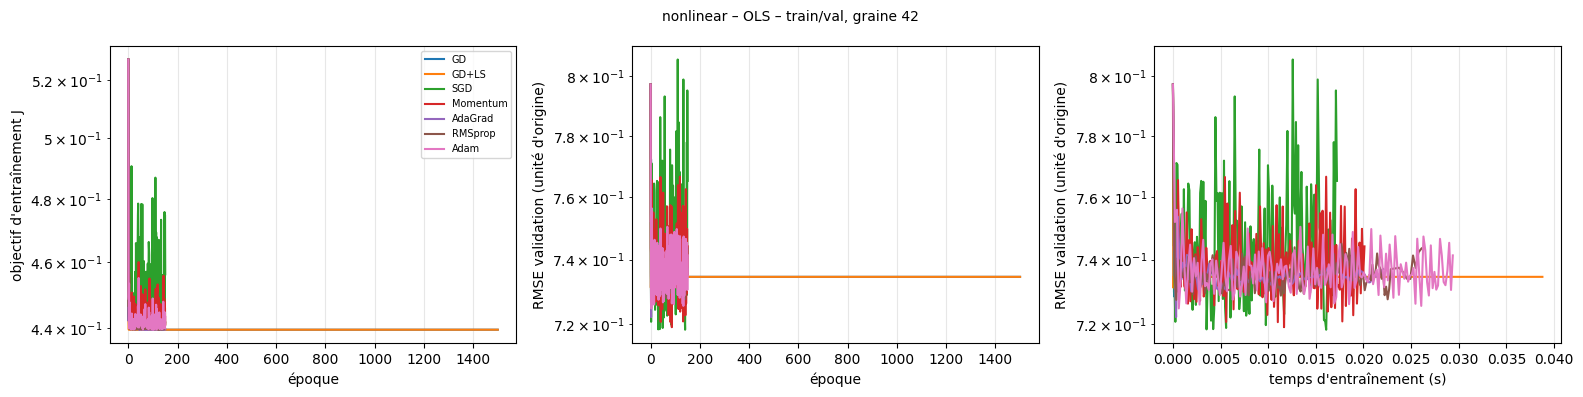

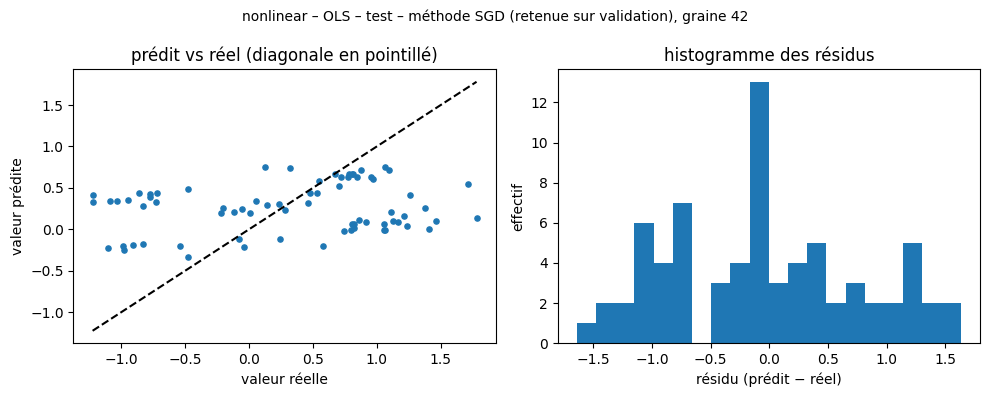

  nonlinear/ridge GD        eta=1.386015148165365 val=0.7258
  nonlinear/ridge GD+LS     eta=None val=0.7313
  nonlinear/ridge SGD       eta=0.7294816569291396 val=0.7181
  nonlinear/ridge Momentum  eta=0.14589633138582792 val=0.719
  nonlinear/ridge AdaGrad   eta=0.3 val=0.7234
  nonlinear/ridge RMSprop   eta=0.03 val=0.726
  nonlinear/ridge Adam      eta=0.1 val=0.7231


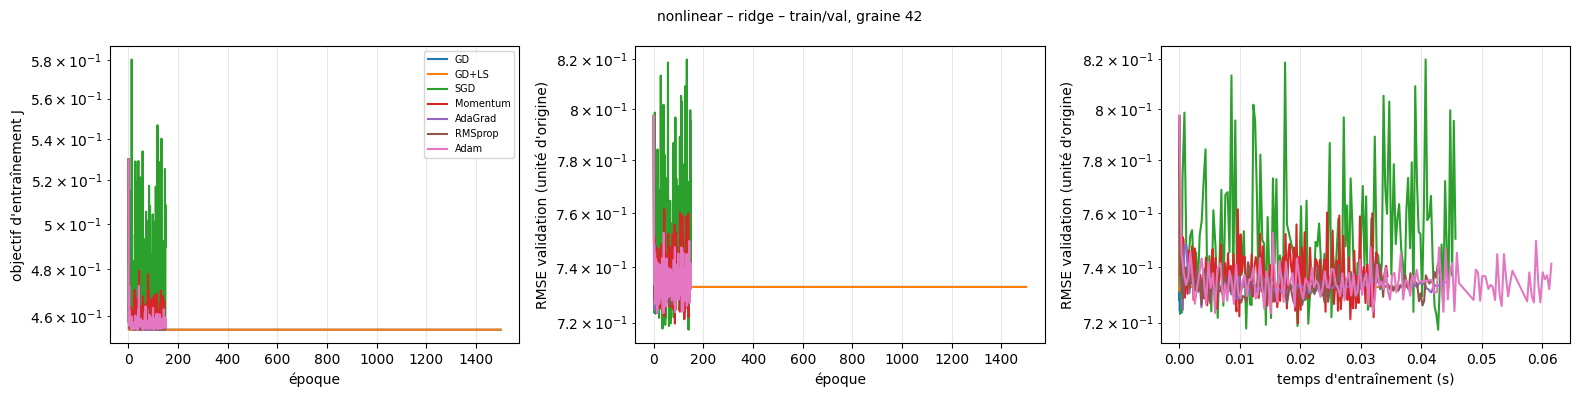

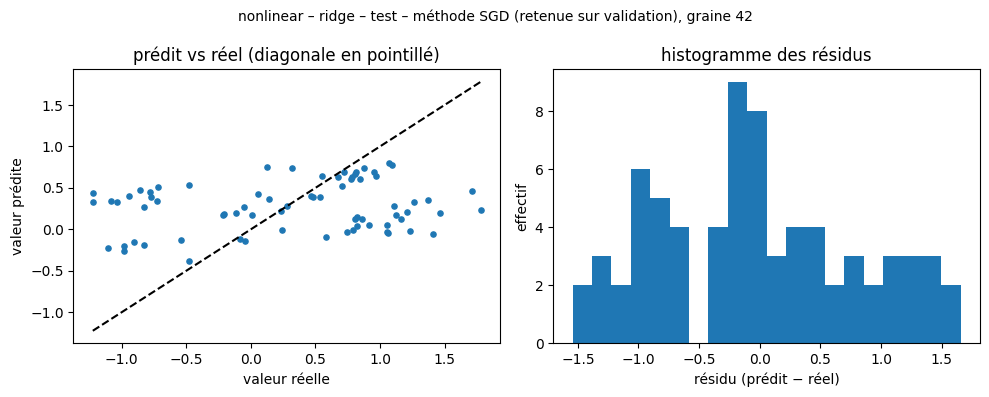

  nonlinear/kernel-ridge GD        eta=0.20871625781180178 val=0.31
  nonlinear/kernel-ridge GD+LS     eta=None val=0.3003
  nonlinear/kernel-ridge SGD       eta=0.10985066200621146 val=0.3686
  nonlinear/kernel-ridge Momentum  eta=0.05492533100310573 val=0.2559
  nonlinear/kernel-ridge AdaGrad   eta=0.3 val=0.35
  nonlinear/kernel-ridge RMSprop   eta=0.01 val=0.3286
  nonlinear/kernel-ridge Adam      eta=0.1 val=0.2177


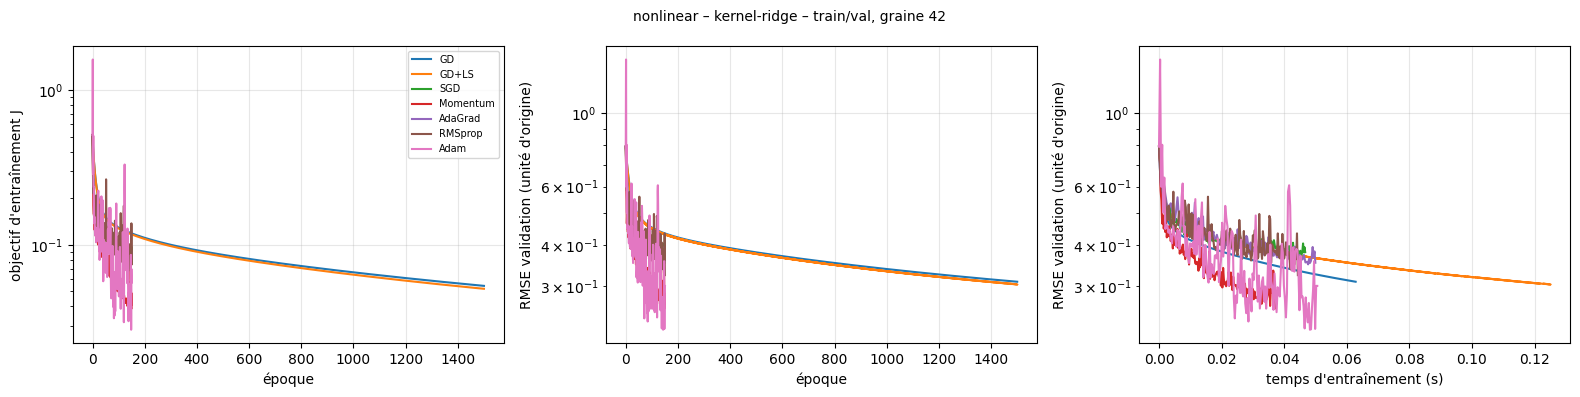

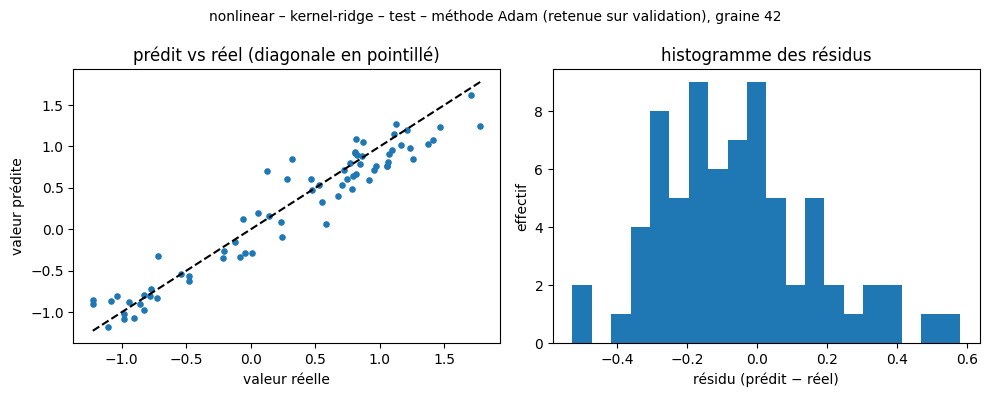

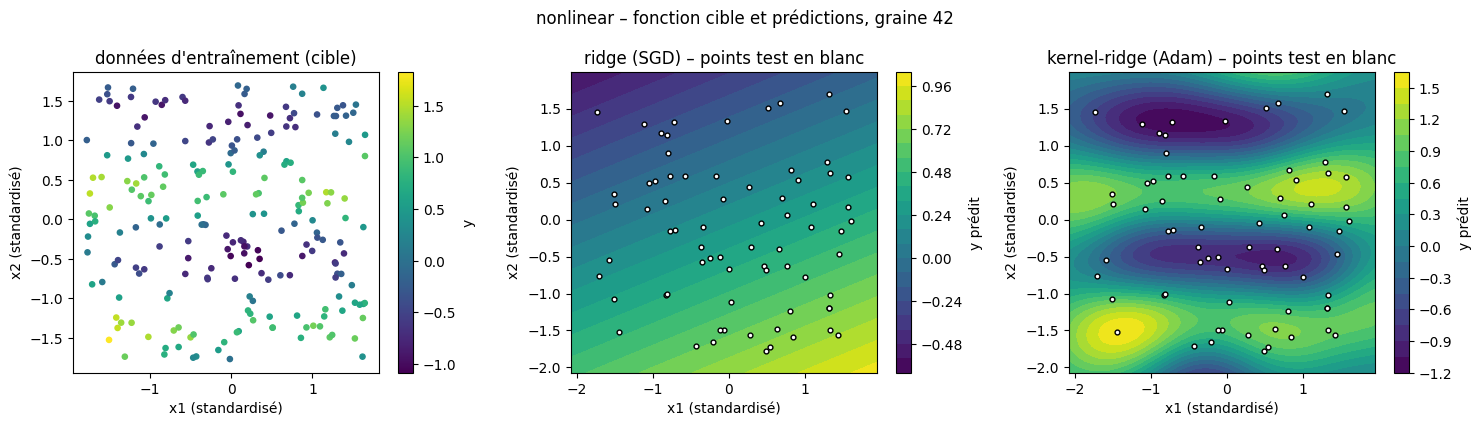

absent : regression_diabetes.csv

=== reg : moyenne ± écart type sur 3 graine(s) ===
  dataset        model      lam    sigma   method  n_seeds   best_epoch         best_val          test_mse        test_rmse         test_mae            test_r2            time_s  updates grad_calls loss_calls
nonlinear          OLS 0.000000      NaN       GD        3 11.67 ± 0.94  0.7298 ± 0.0015  0.6857 ± 0.00069 0.8281 ± 0.00042  0.6879 ± 0.0042   -0.01207 ± 0.001  0.02119 ± 0.0023 1500 ± 0   1500 ± 0      0 ± 0
nonlinear          OLS 0.000000      NaN    GD+LS        3        1 ± 0 0.7315 ± 0.00065   0.6803 ± 0.0015 0.8248 ± 0.00089  0.695 ± 0.00073 -0.004117 ± 0.0022   0.04053 ± 0.004 1500 ± 0   1500 ± 0      0 ± 0
nonlinear          OLS 0.000000      NaN      SGD        3      88 ± 56 0.7176 ± 0.00048   0.6683 ± 0.0033   0.8175 ± 0.002 0.6725 ± 0.00078   0.01371 ± 0.0048 0.01721 ± 5.4e-05 1050 ± 0   1050 ± 0      0 ± 0
nonlinear          OLS 0.000000      NaN Momentum        3   58.67 ± 37 0.7197 

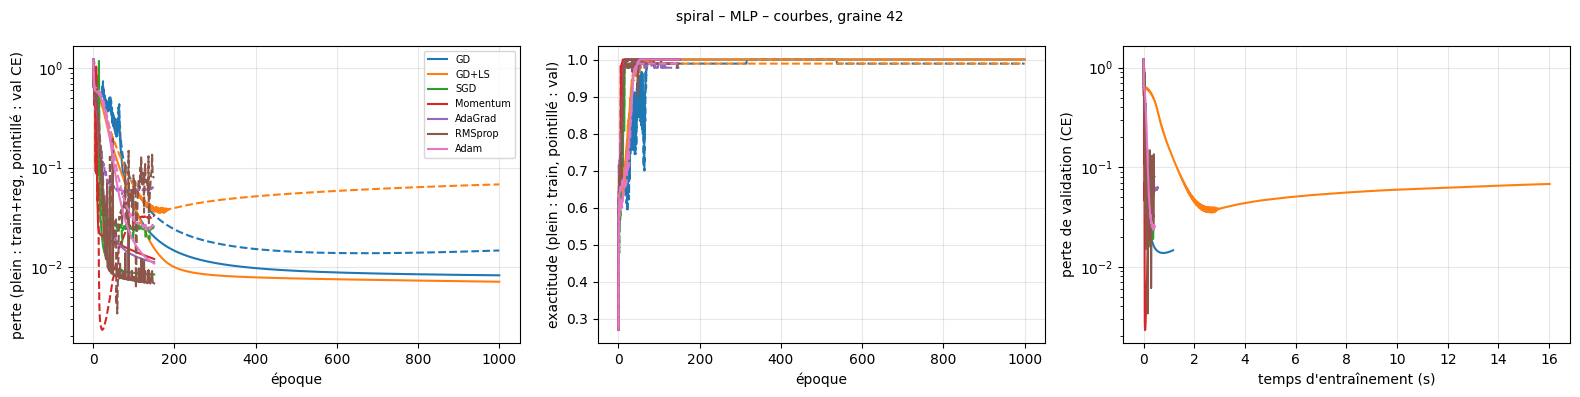

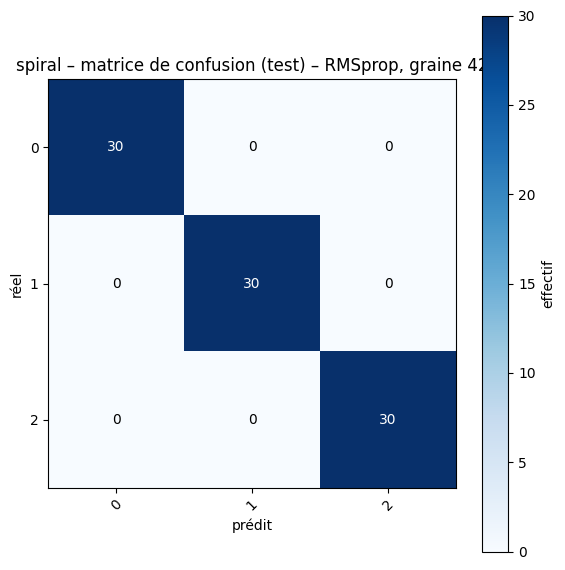

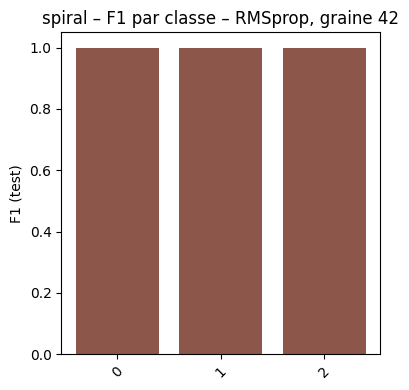

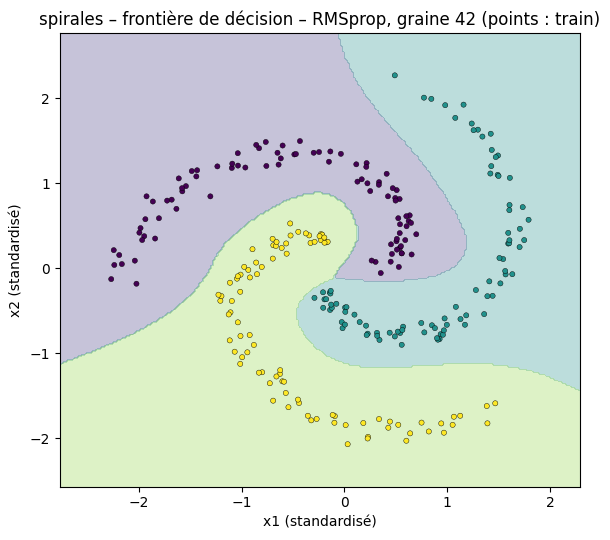

absent : classification_iris.csv
absent : mnist_50k_10k_10k.npz
absent : fashion_mnist_50k_10k_10k.npz

=== clf : moyenne ± écart type sur 3 graine(s) ===
dataset   method  n_seeds      best_epoch         best_val        test_acc       test_prec        test_rec         test_f1           test_ce          time_s  updates grad_calls  loss_calls
 spiral       GD        3 579.7 ± 2.4e+02   0.016 ± 0.0054 0.9963 ± 0.0052 0.9964 ± 0.0051 0.9963 ± 0.0052 0.9963 ± 0.0052 0.009959 ± 0.0037   1.225 ± 0.091 1000 ± 0   1000 ± 0       0 ± 0
 spiral    GD+LS        3        218 ± 87   0.02369 ± 0.01 0.9926 ± 0.0052 0.9928 ± 0.0051 0.9926 ± 0.0052 0.9926 ± 0.0052   0.01799 ± 0.011    16.07 ± 0.16 1000 ± 0   1000 ± 0 1.4e+04 ± 0
 spiral      SGD        3      95.67 ± 25 0.02092 ± 0.0099 0.9926 ± 0.0052 0.9928 ± 0.0051 0.9926 ± 0.0052 0.9926 ± 0.0052   0.0142 ± 0.0058 0.4006 ± 0.0059 1350 ± 0   1350 ± 0       0 ± 0
 spiral Momentum        3      28.67 ± 19  0.02498 ± 0.017 0.9926 ± 0.0052 0.9928 ± 0.005

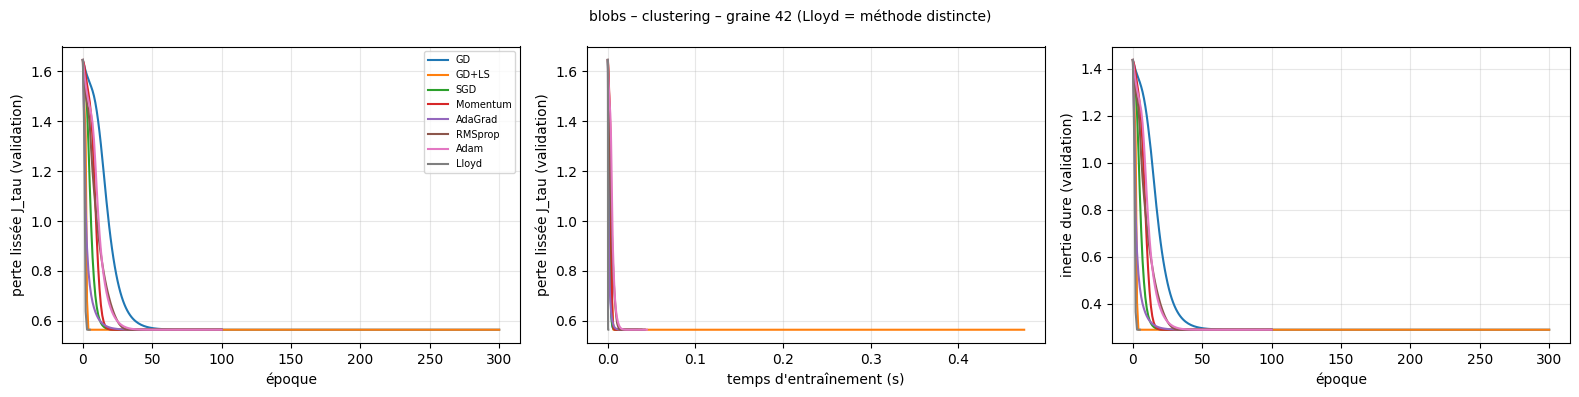

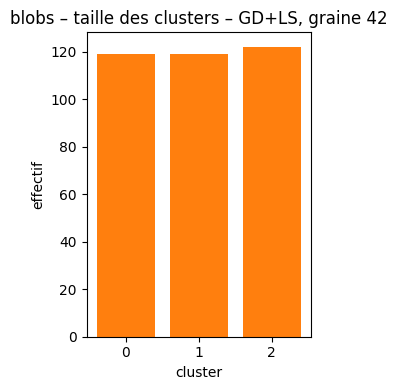

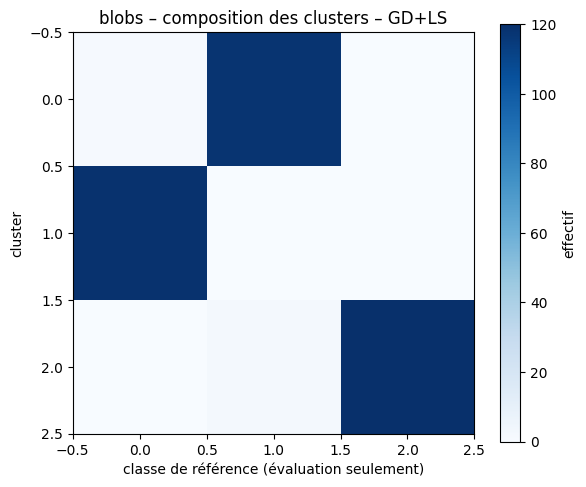

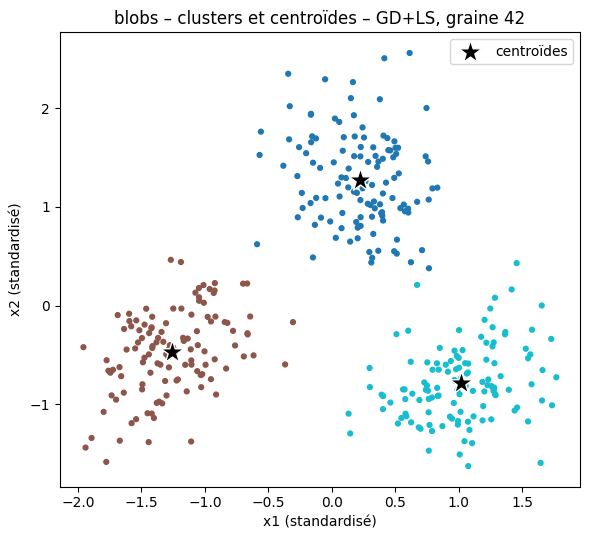

absent : clustering_wine.csv
absent : mnist_50k_10k_10k.npz
absent : fashion_mnist_50k_10k_10k.npz

=== clu : moyenne ± écart type sur 3 graine(s) ===
dataset   method  n_seeds   best_epoch         best_val        soft_loss          inertia nonempty silhouette        ari        nmi              time_s      updates grad_calls loss_calls
  blobs       GD        3  297.3 ± 3.1 0.5643 ± 1.1e-16 0.5643 ± 1.1e-16 0.2903 ± 8.4e-12    3 ± 0 0.6793 ± 0 0.9751 ± 0 0.9596 ± 0   0.03374 ± 0.00041      300 ± 0    300 ± 0      0 ± 0
  blobs    GD+LS        3  14.67 ± 4.6       0.5643 ± 0       0.5643 ± 0 0.2903 ± 1.8e-13    3 ± 0 0.6793 ± 0 0.9751 ± 0 0.9596 ± 0      0.4684 ± 0.006      300 ± 0    300 ± 0   4200 ± 0
  blobs      SGD        3  87.67 ± 9.5 0.5643 ± 8.7e-07 0.5643 ± 8.7e-07 0.2903 ± 1.1e-06    3 ± 0 0.6793 ± 0 0.9751 ± 0 0.9596 ± 0   0.03764 ± 0.00057      600 ± 0    600 ± 0      0 ± 0
  blobs Momentum        3   67.33 ± 13 0.5643 ± 3.6e-07 0.5643 ± 3.6e-07 0.2903 ± 5.9e-07    3 ± 0 0.

In [ ]:
main()

In [ ]:
make_zip('resultats.zip')
from google.colab import files
files.download('resultats.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>